# Gearbox verification: output shaft A2, pinions R1 and R3, bearings A-D

**Fundamentals of Machine Design, Politecnico di Torino, A.Y. 2024/2025, Group 27. REVISED EDITION**

This notebook redoes the whole calculation from the project brief , step by step, from top to bottom:

1. Input data
2. Gear geometry and kinematics
3. Mesh forces
4. Support reactions and axial bearing loads
5. Internal loads along shaft A2
6. Static check of A2
7. Fatigue check of A2
8. AGMA check of pinions R1 and R3
9. SKF life of bearings A-D
10. Consistency checks

**Notes on unites:** N, mm, N.mm and MPa inside the calculations. Moments are converted to N.m for printing

In [1]:
import json
import numpy as np
import matplotlib.pyplot as plt

from math import pi, sin, cos, tan, atan, sqrt, log, radians, degrees
from pathlib import Path


FIG=Path('figures')
FIG.mkdir(exist_ok=True)


## 1. Input data

In [2]:
P_IN= 6000 #W
N_IN= 2500 #rpm , input shaft A1 (rot +z)

# helical gears
MN= 2.5 #mm
PSI = radians(20) #helix angle
PHI_N= radians(20) #normal helix pressure
FACE =30 # mm , face width
QV= 7 #transmission accuracy level
Z= {'R1':18, 'R2': 73, 'R3': 19, 'R4': 51 }

HAND = {"R1": "right", "R2": "left", "R3": "left", "R4": "right"}

GEAR_MAT= { 
          # sigma_u, sigma_y [MPa], HB, sigma_FP, sigma_HP [MPa]
    "R1": dict(su=1060, sy=950, HB=335, sFP=320, sHP=860),
    "R2": dict(su=1950, sy=1400, HB=560, sFP=450, sHP=1360),
    "R3": dict(su=1950, sy=1400, HB=560, sFP=450, sHP=1360),
    "R4": dict(su=1060, sy=950, HB=335, sFP=320, sHP=860),
}

# Shaft A2 material:
SU_SHAFT, SY_SHAFT, SD_1 = 1050, 950, 520 #MPa , rotating bending fatigue limit

# SKF bearings (catalogue AA2024)
BEARINGS = {
    "30203": dict(d=17, D=40, T=13.25, C=23.4e3, C0=18.6e3, Pu=1.83e3, a=9, e=0.35, Y=1.7, Y0=0.9),
    "30208": dict(d=40, D=80, T=19.75, C=75.8e3, C0=68.0e3, Pu=7.65e3, a=16, e=0.37, Y=1.6, Y0=0.9),
}

#SKF life factors
FRM_FACTOR = 0.017 
A1_RELIABILITY = 0.64 # 95% reliability
ETA_C = 0.4 # slight contamination
NU_OIL_60C = 40.0 #mm2/s, ISO VG 100 at 60 C
EXPLORER_SHIFT = 1.39

# Geometry 
# for bearing A . SKF 30203 : T=13.25 mm, a =9 mm, back to back mounting (centers shifted outboard)

B1, B2 = BEARINGS["30203"], BEARINGS["30208"]     # shaft A1 and shaft A2 bearings

# Drawing dimensions (brief, Figures 3 and 4), mm
GAP_A_B= 28.75  # between the facing sides of bearings A and B
B_TO_R1= 24.25 # side of B to the face of R1
L2_START= 17.0  # keyseat L2 (gear R4)
L2_LENGTH= 18.0
SHOULDER_V2= 46.0# shoulder d35/d40
SPACER= 9.25  # between the shoulder and bearing C
GAP_C_D= 25.0  # between the facing sides of C and D
D_TO_STEP= 58.5  # side of D to the step d34/d32
STEP_TO_L3_MID= 35.0  # step to the middle of keyseat L3
KEYSEAT_DEPTH = 5.0
L3_LENGTH = 20.0# keyseat L3
STEP_V3 = 133.0 # shoulder
A2_LENGTH = 223.0
D_L2, D_SEATS, D_V3, D_L3 = 35.0, 40.0, 34.0, 32.0 # diameters, left to right

# Shaft A1, origin at the pressure centre of bearing A
A1_ZA  = 0.0
A1_ZB  = B1["a"] + GAP_A_B + B1["a"]                
A1_ZR1 = A1_ZB + (B1["T"] - B1["a"]) + B_TO_R1 + FACE / 2  
# Shaft A2, origin at the left end
A2_ZR   = L2_START + L2_LENGTH / 2   
A2_ZC   = SHOULDER_V2 + SPACER + (B2["T"] - B2["a"]) 
A2_ZD   = A2_ZC + B2["a"] + GAP_C_D + B2["a"]  
A2_ZOUT = (A2_ZD - B2["a"]) + D_TO_STEP + STEP_TO_L3_MID 

L2_END = L2_START + L2_LENGTH 
STEP_L3 = (A2_ZD - B2["a"]) + D_TO_STEP 
L3_START = A2_ZOUT - L3_LENGTH / 2 
L3_END = A2_ZOUT + L3_LENGTH / 2

#    (z start,    z end,    nominal d, static d)
A2_PROFILE = [
    (0.0,         L2_START,    D_L2,    D_L2),
    (L2_START,    L2_END,      D_L2,    D_L2 - KEYSEAT_DEPTH),
    (L2_END,      SHOULDER_V2, D_L2,    D_L2),
    (SHOULDER_V2, STEP_V3,     D_SEATS, D_SEATS),#seats + thread
    (STEP_V3,     STEP_L3,     D_V3,    D_V3),
    (STEP_L3,     L3_START,    D_L3,    D_L3),
    (L3_START,    L3_END,      D_L3,    D_L3 - KEYSEAT_DEPTH),# keyseat L3
    (L3_END,      A2_LENGTH,   D_L3,    D_L3),
]

Z_V1, Z_V2, Z_V3 = A2_ZR, SHOULDER_V2, STEP_V3

#fatigue data for sections V1-V3 
SECTIONS = {
    # V1: keyseat L2 on d35, Kf given by the brief (bending 1.6, torsion 2.0; bending value used for axial)
    "V1": dict(z=Z_V1, d=D_L2, D=None, kind="keyseat", Kf_B=1.6, Kf_N=1.6, Kf_T=2.0, Ra=0.6),
    # V2: shoulder d35/D40, fillet r = 1 mm -> r/d = 0.029
    "V2": dict(z=Z_V2, d=D_L2, D=D_SEATS, kind="shoulder", Ra=0.8),
    # V3: shoulder d34/M40 (taken as D40), r = 1 mm -> r/d = 0.029
    "V3": dict(z=Z_V3, d=D_V3, D=D_SEATS, kind="shoulder", Ra=0.5),
}


# Kt read at r/d= 0.029 as {D/d: Kt}; linear in D/d between the 2 curves
KT_BENDING ={1.1: 2.2, 1.5: 2.43}
KT_TORSION = {1.1: 1.41, 1.2: 1.82}
KT_AXIAL = {1.05: 2.05, 1.2: 2.67} 
NOTCH_Q = 0.86 # notch sensitivity, r = 1 mm, sigma_u = 1.05 GPa
CS = {D_L2: 0.845, D_V3: 0.85} # size factor
CF = 1.0  # surface factor (Ra<= 0.8 um)

# AGMA data (brief)
K0, CMC, CE = 1, 1, 1 
CPM={'R1':1.1,
     'R3':1}

R3_HUB_D= 30 #mm
LEWIS_Y = {21:0.328, 22:0.331, 24:0.337} # by virtual nb of teeth 
J1 = {20: 0.503, 30: 0.548} # J'  (helix 20 deg) by actual teeth
J2 = {50: 0.983, 75: 1.000} # J'' by teeth of the mating gear
ZE, ZR, Y_THETA, YZ = 191.0, 1.0, 1.0, 1.0 # steel/steel, T = 60 C, reliability 0.99
N_CYCLES = 1e8

## 2. Gear geometry and kinematics

$m_t = m_n/\cos\psi$
$\;\tan\varphi_t=\tan\varphi_n/\cos\psi$,
$\;d = m_t z$

The input shaft turns about $+z$. Each external mesh reverses the direction rotation, so after two meshes A2 turns about $+z$ again.
Efficiency is 1 (brief), so the torque grows by each gear ratio.

In [3]:
MT = MN / cos(PSI) #transverse module, mm
PHI_T = atan(tan(PHI_N) / cos(PSI)) #transverse pressure angle
d = {g: MT * Z[g] for g in Z} #pitch diameters, mm
r = {g: d[g] /
 2 for g in Z}

w_in = 2 * pi * N_IN / 60
omega = {"A1": w_in}
omega["P"] = -omega["A1"] * Z["R1"] / Z["R2"] 
omega["A2"] = -omega["P"] * Z["R3"] / Z["R4"]
rpm = {k: omega[k] * 60 / (2 * pi) for k in omega}

T = {"A1": P_IN / w_in}
T["P"] = T["A1"] * Z["R2"] / Z["R1"]
T["A2"] = T["P"] * Z["R4"] / Z["R3"]

## 3. Mesh forces as vectors

$F_t = T/r$, $\;F_r = F_t\tan\varphi_t$, $\;F_a = F_t\tan\psi$.

Each force is built as a 3-D vector from the geometry:
- **Tangential:** the contact point is on the line joining the two gear centres. The force opposes the contact-point velocity on the driving gear and follows it on the driven gear.
- **Radial:** points towards the gear's own axis.
- **Axial:** follows from the tooth normal, which is perpendicular to the helix. This gives its direction for a right- or left-hand helix.

R1 meshes with R2
R4 meshes with R3 
Forces on R2 and R3 are only used to check action = reaction

In [4]:
Ft12 = T["A1"] / (r["R1"] / 1000) # N
Ft34 = T["P"] / (r["R3"] / 1000)

ez = np.array([0.0, 0.0, 1.0])
ey = np.array([0.0, 1.0, 0.0])

# (gear, tangential force, angular velocity of that gear, is it the driver?, contact at y = side * r)
mesh_cases = [("R1", Ft12, omega["A1"], True, -1),
              ("R4", Ft34, omega["A2"], False, -1),
              ("R2", Ft12, omega["P"], False, +1),
              ("R3", Ft34, omega["P"], True, +1)]
F, pos = {}, {}

for gear, Ft, w, driver, side in mesh_cases:
    rr = r[gear] / 1000 #m
    p = np.array([0.0, side * rr, 0.0]) # contact point
    v = np.cross(w * ez, p)    # contact point velocity
    Ft_vec = (-Ft if driver else Ft) * v / np.linalg.norm(v)
    Fr_vec = -side * Ft * tan(PHI_T) * ey # towards the gear axis
    e_theta = np.cross(ez, p / rr)  # circumferential direction
    hand = +1 if HAND[gear] == "right" else -1
    helix = sin(PSI) * e_theta * hand + cos(PSI) * ez  # tooth direction
    n = cos(PSI) * e_theta - sin(PSI) * hand * ez # tooth normal in the (theta, z) plane
    assert abs(helix @ n) < 1e-12
    k = (Ft_vec @ e_theta) / (n @ e_theta) # scale so the tangential part equals Ft
    F[gear] = k * n + Fr_vec
    pos[gear] = p

forces = {"Ft12": Ft12, "Fr12": Ft12 * tan(PHI_T), "Fa12": Ft12 * tan(PSI),
          "Ft34": Ft34, "Fr34": Ft34 * tan(PHI_T), "Fa34": Ft34 * tan(PSI)}

for g in ("R1", "R4"):
    print(f"force on {g} (x, y, z) = ({F[g][0]:9.2f}, {F[g][1]:9.2f}, {F[g][2]:9.2f}) N")

force on R1 (x, y, z) = (  -957.16,    370.74,    348.38) N
force on R4 (x, y, z) = (  3677.52,   1424.41,  -1338.51) N


## 4. Support reactions and axial bearing loads

Each shaft rests on two bearings at their pressure centers. Equilibrium is solved in the x-z and y-z planes. The axial gear force acts at the pitch radius, so it adds a concentrated moment $F_a\,r$, which appears **only in the y–z plane** because the contact point lies on the y axis.

On A2 (brief): $F_{r,out} = T_{A2}/0.1$ in $+y$  and   $F_{a,out} = 0.25\,F_{r,out}$ in $-z$

In [5]:
Fout = np.array([0.0, T["A2"] / 0.1, -0.25 * T["A2"] / 0.1])# N
Mx_axial = {"A1": pos["R1"][1] * 1000 * F["R1"][2], # y * Fz, N·mm
            "A2": pos["R4"][1] * 1000 * F["R4"][2]}

#supports z1, z2;point loads (z, Fx, Fy);couples (z, Mx, My)
shafts = {
    "A1": dict(z1=A1_ZA, z2=A1_ZB,
               loads=[(A1_ZR1, F["R1"][0], F["R1"][1])],
               couples=[(A1_ZR1, Mx_axial["A1"], 0.0)]),
    "A2": dict(z1=A2_ZC, z2=A2_ZD,
               loads=[(A2_ZR, F["R4"][0], F["R4"][1]), (A2_ZOUT, Fout[0], Fout[1])],
               couples=[(A2_ZR, Mx_axial["A2"], 0.0)]),
}
reactions = {}
for name, s in shafts.items():
    z1, z2 = s["z1"], s["z2"]
    SFx = sum(L[1] for L in s["loads"])
    SFy = sum(L[2] for L in s["loads"])
    SMy = sum(L[0] * L[1] for L in s["loads"]) + sum(c[2] for c in s["couples"])
    SMx = sum(-L[0] * L[2] for L in s["loads"]) + sum(c[1] for c in s["couples"])
    R2x = (-SMy + z1 * SFx) / (z2 - z1); R1x = -SFx - R2x      # sum Fx = 0, sum My = 0
    R2y = (SMx + z1 * SFy) / (z2 - z1); R1y = -SFy - R2y       # sum Fy = 0, sum Mx = 0
    reactions[name] = (R1x, R1y, R2x, R2y)
RxA, RyA, RxB, RyB = reactions["A1"]
RxC, RyC, RxD, RyD = reactions["A2"]

Ka_A1 = F["R1"][2]                  # net external axial load on each shaft
Ka_A2 = F["R4"][2] + Fout[2]
print(f"A1: RxA = {RxA:8.1f}  RyA = {RyA:8.1f}  RxB = {RxB:8.1f}  RyB = {RyB:8.1f} N,  Ka = {Ka_A1:7.1f} N")
print(f"A2: RxC = {RxC:8.1f}  RyC = {RyC:8.1f}  RxD = {RxD:8.1f}  RyD = {RyD:8.1f} N,  Ka = {Ka_A2:7.1f} N")

A1: RxA =   -890.6  RyA =    523.4  RxB =   1847.8  RyB =   -894.1 N,  Ka =   348.4 N
A2: RxC =  -5806.6  RyC =   -450.0  RxD =   2129.1  RyD =  -3469.3 N,  Ka = -1962.2 N


**Axial bearing loads (SKF table 7, back to back mounting)**.

Each tapered roller bearing produces an internal axial force $0.5F_r/Y$. The left bearing (A, C) resists the shaft moving towards $+z$, and the right one (B, D) resists it moving towards $-z$. The bearing that carries the external load $K_a$ is called "thrust" below, and the other one "free".

| Case | Condition | $F_{a,\text{free}}$ | $F_{a,\text{thrust}}$ |
|---|---|---|---|
| 1a | $F_{r,\text{free}}/Y \ge F_{r,\text{thrust}}/Y$ | $0.5F_{r,\text{free}}/Y$ | $F_{a,\text{free}}+K_a$ |
| 1b | $K_a \ge 0.5\,(F_{r,\text{thrust}}/Y - F_{r,\text{free}}/Y)$ | $0.5F_{r,\text{free}}/Y$ | $F_{a,\text{free}}+K_a$ |
| 1c | otherwise | $F_{a,\text{thrust}}-K_a$ | $0.5F_{r,\text{thrust}}/Y$ |

In [6]:
#(left bearing, right bearing, Fr left, Fr right, Ka, series, speed)
pairs = [("A", "B", np.hypot(RxA, RyA), np.hypot(RxB, RyB), Ka_A1, "30203", abs(rpm["A1"])),
         ("C", "D", np.hypot(RxC, RyC), np.hypot(RxD, RyD), Ka_A2, "30208", abs(rpm["A2"]))]
bear = {}
for left, right, Fr_left, Fr_right, Ka, series, n in pairs:
    Y = BEARINGS[series]["Y"]
    if Ka >= 0:      # shaft pushed towards +z: the left bearing carries Ka
        thrust, Fr_thr, free, Fr_free, Ka_abs = left, Fr_left, right, Fr_right, Ka
    else:
        thrust, Fr_thr, free, Fr_free, Ka_abs = right, Fr_right, left, Fr_left, -Ka
    if Fr_free / Y >= Fr_thr / Y:
        case = "1a"; Fa_free = 0.5 * Fr_free / Y; Fa_thr = Fa_free + Ka_abs
    elif Ka_abs >= 0.5 * (Fr_thr / Y - Fr_free / Y):
        case = "1b"; Fa_free = 0.5 * Fr_free / Y; Fa_thr = Fa_free + Ka_abs
    else:
        case = "1c"; Fa_thr = 0.5 * Fr_thr / Y; Fa_free = Fa_thr - Ka_abs
    bear[free] = dict(series=series, n=n, Fr=Fr_free, Fa=Fa_free, case=case)
    bear[thrust] = dict(series=series, n=n, Fr=Fr_thr, Fa=Fa_thr, case=case)
bear = {k: bear[k] for k in "ABCD"}

RzC = -bear["C"]["Fa"] 
RzD = +bear["D"]["Fa"]
for k, b in bear.items():
    print(f"bearing {k} ({b['series']}): Fr = {b['Fr']:7.1f} N   Fa = {b['Fa']:7.1f} N   case {b['case']}")
print(f"RzC = {RzC:.1f} N,  RzD = {RzD:.1f} N")

bearing A (30203): Fr =  1033.0 N   Fa =   952.1 N   case 1a
bearing B (30203): Fr =  2052.7 N   Fa =   603.7 N   case 1a
bearing C (30208): Fr =  5824.0 N   Fa =  1820.0 N   case 1a
bearing D (30208): Fr =  4070.5 N   Fa =  3782.2 N   case 1a
RzC = -1820.0 N,  RzD = 3782.2 N


## 5. Internal loads along shaft A2

At each cut $z$, the internal loads are the sum of the loads to its left:

$N = -\sum F_z$ (tension positive), $\quad M_x = \sum\big[(z-z_i)F_{y,i} + M_{x,i}\big]$, $\quad M_y = -\sum (z-z_i)F_{x,i}$, $\quad M_t=\sum M_{z,i}$, $\quad M_B=\sqrt{M_x^2+M_y^2}$.

The loads from gear R4 and from the end user act at the middle of their keyseats. Where a section coincides with a load, the value just to its right is used.

In [7]:
#point loads on A2: (z, Fx, Fy, Fz, Mx, Mz) in N and N·mm
A2_points = [
    (A2_ZR, F["R4"][0], F["R4"][1], F["R4"][2], Mx_axial["A2"], T["A2"] * 1000),
    (A2_ZC, RxC, RyC, RzC, 0.0, 0.0),
    (A2_ZD, RxD, RyD, RzD, 0.0, 0.0),
    (A2_ZOUT, Fout[0], Fout[1], Fout[2], 0.0, -T["A2"] * 1000),
]

zz = np.linspace(0, A2_LENGTH, 2231) # 0.1 mm steps
N_z = np.zeros_like(zz)
Mx_z = np.zeros_like(zz)
My_z = np.zeros_like(zz)
Mt_z = np.zeros_like(zz)
for zi, Fx, Fy, Fz, Mxi, Mzi in A2_points:
    on_left = zz >= zi  # this load is on the left of the cut
    N_z = N_z - Fz * on_left
    Mx_z = Mx_z + ((zz - zi) * Fy + Mxi) * on_left
    My_z = My_z - (zz - zi) * Fx * on_left
    Mt_z = Mt_z + Mzi * on_left
Mb_z = np.hypot(Mx_z, My_z)

#diameters along the shaft (the first segment that contains z wins)
d_nom = np.full_like(zz, np.nan)
d_st = np.full_like(zz, np.nan)
for z0, z1, dn, ds in A2_PROFILE:
    inside = (zz >= z0) & (zz <= z1) & np.isnan(d_nom)
    d_nom[inside] = dn
    d_st[inside] = ds

#the same sums at the three required sections
section_loads = {}
for name, sec in SECTIONS.items():
    N = Mx = My = Mt = 0.0
    for zi, Fx, Fy, Fz, Mxi, Mzi in A2_points:
        if zi <= sec["z"]:
            N -= Fz
            Mx += (sec["z"] - zi) * Fy + Mxi
            My += -(sec["z"] - zi) * Fx
            Mt += Mzi
    section_loads[name] = dict(z=sec["z"], N=N, Mx=Mx, My=My, Mb=np.hypot(Mx, My), Mt=Mt)
    print(f"{name} (z = {sec['z']:5.1f}): N = {N:8.1f} N  Mx = {Mx/1000:7.2f}  My = {My/1000:7.2f}  "
          f"MB = {np.hypot(Mx, My)/1000:7.2f}  Mt = {Mt/1000:7.2f} N·m")
i_max = int(np.argmax(Mb_z))
print(f"maximum bending moment {Mb_z[i_max]/1000:.2f} N·m at z = {zz[i_max]:.1f} mm")

V1 (z =  26.0): N =   1338.5 N  Mx =   90.81  My =    0.00  MB =   90.81  Mt =  249.49 N·m
V2 (z =  46.0): N =   1338.5 N  Mx =  119.29  My =  -73.55  MB =  140.15  Mt =  249.49 N·m
V3 (z = 133.0): N =   -623.7 N  Mx =  150.94  My =   -0.00  MB =  150.94  Mt =  249.49 N·m
maximum bending moment 193.35 N·m at z = 116.0 mm


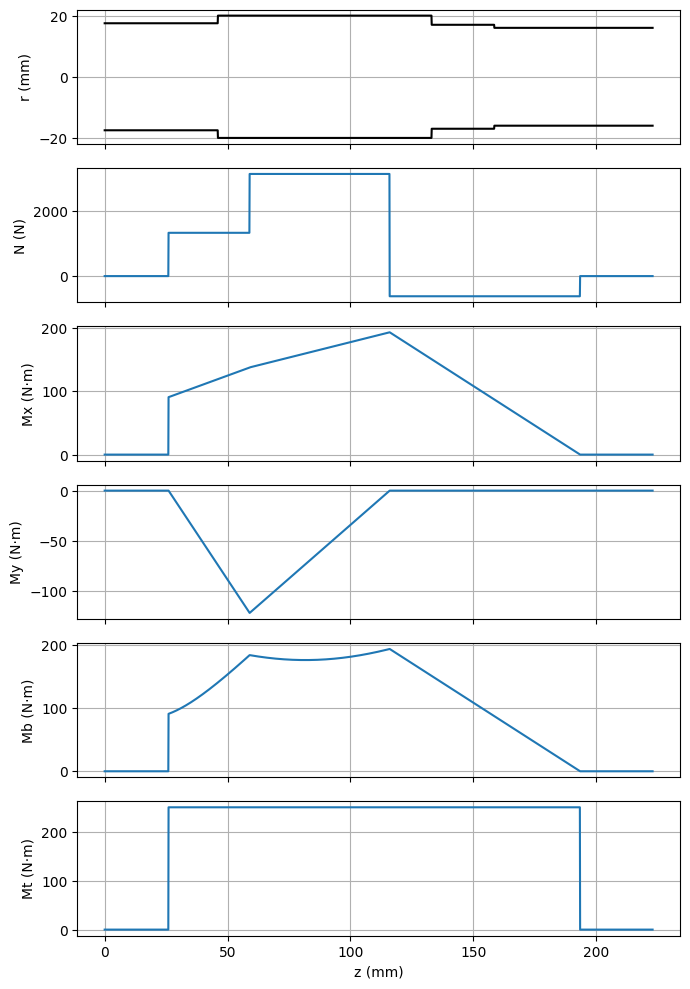

In [8]:
fig, axs = plt.subplots(6, 1, figsize=(7, 10), sharex=True)

axs[0].plot(zz, d_nom / 2, "k")
axs[0].plot(zz, -d_nom / 2, "k")
axs[0].set_ylabel("r (mm)")

axs[1].plot(zz, N_z);         axs[1].set_ylabel("N (N)")
axs[2].plot(zz, Mx_z / 1000); axs[2].set_ylabel("Mx (N·m)")
axs[3].plot(zz, My_z / 1000); axs[3].set_ylabel("My (N·m)")
axs[4].plot(zz, Mb_z / 1000); axs[4].set_ylabel("Mb (N·m)")
axs[5].plot(zz, Mt_z / 1000); axs[5].set_ylabel("Mt (N·m)")

for ax in axs:
    ax.grid(True)
axs[-1].set_xlabel("z (mm)")

plt.tight_layout()
plt.savefig(FIG / "internal_loads.png", dpi=150)
plt.show()

## 6. Static check of shaft A2


$\sigma_N = N/A$, $\;\sigma_{M_B} = 32M_B/(\pi d^3)$, $\;\tau = 16M_t/(\pi d^3)$, $\;\sigma_{tot} = |\sigma_N| + \sigma_{M_B}$ (the worst outer fibre), $\;\sigma_{id} = \sqrt{\sigma_{tot}^2+3\tau^2}$, $\;SF = \sigma_y/\sigma_{id}$.

The static diameter is the nominal diameter minus the 5 mm keyseat depth at keyseats, and the smaller diameter at shoulders.

In [9]:
#along the whole shaft (static diameters)
A_z = pi * d_st ** 2 / 4
W_z = pi * d_st ** 3 / 32
sN_z = N_z / A_z
sM_z = Mb_z / W_z
tau_z = Mt_z / (2 * W_z)
stot_z = np.abs(sN_z) + sM_z
sid_z = np.sqrt(stot_z ** 2 + 3 * tau_z ** 2)
SF_static_z = np.full_like(zz, np.inf)
SF_static_z[sid_z > 0] = SY_SHAFT / sid_z[sid_z > 0]

#at the required sections
static_sections = {}
for name, sec in SECTIONS.items():
    L = section_loads[name]
    ds = sec["d"] - KEYSEAT_DEPTH    if sec["kind"] == "keyseat" else sec["d"]
    A, W = pi * ds ** 2 / 4, pi * ds ** 3 / 32
    sN, sM, tau = L["N"] / A, L["Mb"] / W, L["Mt"] / (2 * W)
    stot = abs(sN) + sM
    sid = sqrt(stot ** 2 + 3 * tau ** 2)
    static_sections[name] = dict(d=ds, A=A, W=W, sN=sN, sM=sM, tau=tau, stot=stot, sid=sid, SF=SY_SHAFT / sid)
    print(f"{name}: d = {ds:4.1f} mm  sigma_N = {sN:6.2f}  sigma_M = {sM:6.2f}  tau = {tau:6.2f}  "
          f"sigma_id = {sid:6.2f} MPa  SF = {SY_SHAFT / sid:6.2f}")

SF_static_min = min(s["SF"] for s in static_sections.values())
i_sf = int(np.argmin(SF_static_z))
print(f"lowest SF along the whole shaft: {SF_static_z[i_sf]:.2f} at z = {zz[i_sf]:.1f} mm (keyseat L3)")

V1: d = 30.0 mm  sigma_N =   1.89  sigma_M =  34.26  tau =  47.06  sigma_id =  89.17 MPa  SF =  10.65
V2: d = 35.0 mm  sigma_N =   1.39  sigma_M =  33.29  tau =  29.64  sigma_id =  61.95 MPa  SF =  15.33
V3: d = 34.0 mm  sigma_N =  -0.69  sigma_M =  39.12  tau =  32.33  sigma_id =  68.70 MPa  SF =  13.83
lowest SF along the whole shaft: 8.43 at z = 183.6 mm (keyseat L3)


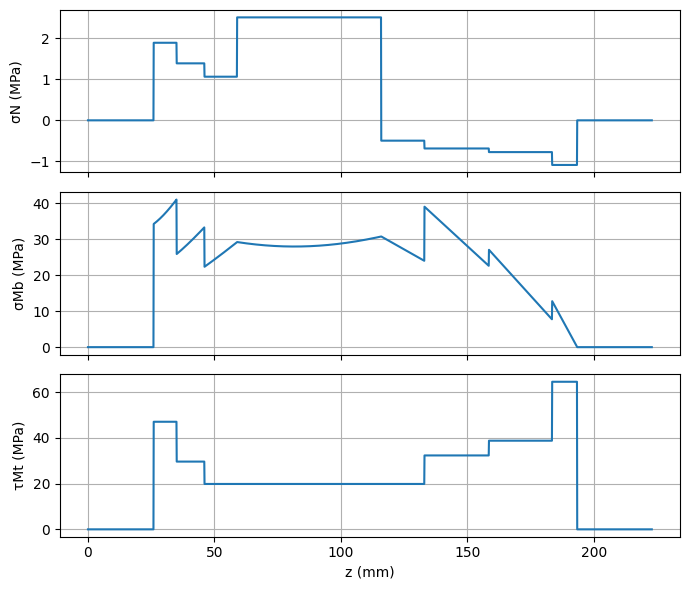

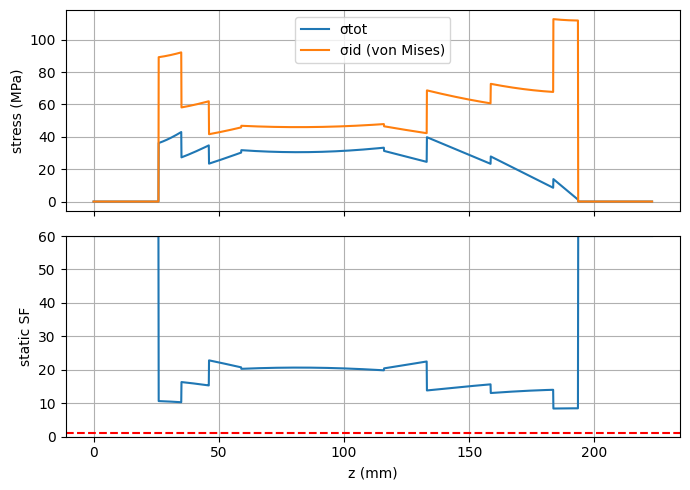

In [10]:
#stress components
fig, axs = plt.subplots(3, 1, figsize=(7, 6), sharex=True)

axs[0].plot(zz, sN_z);  axs[0].set_ylabel("σN (MPa)")
axs[1].plot(zz, sM_z);  axs[1].set_ylabel("σMb (MPa)")
axs[2].plot(zz, tau_z); axs[2].set_ylabel("τMt (MPa)")

for ax in axs:
    ax.grid(True)
axs[-1].set_xlabel("z (mm)")

plt.tight_layout()
plt.savefig(FIG / "stress_components.png", dpi=150)
plt.show()


#equivalent stress and static safety factor
fig, axs = plt.subplots(2, 1, figsize=(7, 5), sharex=True)

axs[0].plot(zz, stot_z, label="σtot")
axs[0].plot(zz, sid_z, label="σid (von Mises)")
axs[0].set_ylabel("stress (MPa)")
axs[0].legend()

axs[1].axhline(1, color="r", ls="--")
axs[1].set_ylim(0, 60)
axs[1].set_ylabel("static SF")
axs[1].plot(zz, np.minimum(SF_static_z, 60))

for ax in axs:
    ax.grid(True)
axs[-1].set_xlabel("z (mm)")

plt.tight_layout()
plt.savefig(FIG / "stress_equivalent.png", dpi=150)
plt.show()

## 7. Fatigue check of shaft A2 (shigley method)

The shaft rotates, so bending is fully reversed. Axial load and torque are constant, so they only contribute mean stresses. Nominal stresses are computed on the full diameter (brief).

- **Shoulder V2, V3:** $K_t$ is read from the charts and converted to $K_f = 1 + q(K_t-1)$. At V1 the brief gives $K_f$ for the keyseat directly.
- **Fatigue limit:** $\sigma_{D-1}^c = C_S\,C_F\,\sigma_{D-1}$.

**Equivalent stresses (Shigley):**

$$\sigma_{a,eq}=\sqrt{\Big(K_{f,B}\sigma_a^B+K_{f,N}\frac{\sigma_a^N}{0.85}\Big)^2+3(K_{f,T}\tau_a)^2}$$

$$\sigma_{m,eq}=\sqrt{\big(K_{f,B}\sigma_m^B+K_{f,N}\sigma_m^N\big)^2+3(K_{f,T}\tau_m)^2}$$


**Safety factor:** all loads scale with the transmitted power, so the SF is measured along the proportional-loading line up to the Goodman line, $1/SF_f = \sigma_{a,eq}/\sigma_{D-1}^c + \sigma_{m,eq}/\sigma_u$. It is also checked against first-cycle yield.

In [11]:
fatigue = {}
for name, sec in SECTIONS.items():
    #Section dimensions and loads
    L = section_loads[name]
    d_sec = sec["d"]
    A = pi * d_sec**2 / 4
    W = pi * d_sec**3 / 32

    # Alternating and mean stresses
    sa_B = L["Mb"] / W
    sm_B = 0
    sa_N = 0
    sm_N = L["N"] / A
    ta_T = 0
    tm_T = L["Mt"] / (2 * W)

    #Fatigue stress concentration factors
    if sec["kind"] == "keyseat":
        KfB = sec["Kf_B"]
        KfN = sec["Kf_N"]
        KfT = sec["Kf_T"]
        Kt = None
        q = None

    else:
        Dd = sec["D"] / d_sec
        q = NOTCH_Q

        (x0, k0), (x1, k1) = sorted(KT_BENDING.items())
        KtB = k0 + (k1 - k0) * (Dd - x0) / (x1 - x0)

        (x0, k0), (x1, k1) = sorted(KT_AXIAL.items())
        KtN = k0 + (k1 - k0) * (Dd - x0) / (x1 - x0)

        (x0, k0), (x1, k1) = sorted(KT_TORSION.items())
        KtT = k0 + (k1 - k0) * (Dd - x0) / (x1 - x0)

        Kt = {"B": KtB, "N": KtN, "T": KtT}
        KfB = 1 + q * (KtB - 1)
        KfN = 1 + q * (KtN - 1)
        KfT = 1 + q * (KtT - 1)
    #Equivalent alternating and mean stresses
    sa_eq = sqrt((KfB * sa_B + KfN * sa_N / 0.85)**2
                 + 3 * (KfT * ta_T)**2)
    sm_eq = sqrt((KfB * sm_B + KfN * sm_N)**2
                 + 3 * (KfT * tm_T)**2)
    #Fatigue safety factors
    Cs = CS[d_sec]
    sD = Cs * CF * SD_1
    SF_goodman = 1 / (sa_eq / sD + sm_eq / SU_SHAFT)
    SF_yield = SY_SHAFT / (sa_eq + sm_eq)

    SF = min(SF_goodman, SF_yield)

    #Store results
    fatigue[name] = {
        "d": d_sec,
        "sa_B": sa_B, "sm_B": sm_B,
        "sa_N": sa_N, "sm_N": sm_N,
        "ta_T": ta_T, "tm_T": tm_T,
        "Kt": Kt, "q": q,
        "KfB": KfB, "KfN": KfN, "KfT": KfT,
        "sa_eq": sa_eq, "sm_eq": sm_eq,
        "Cs": Cs, "Cf": CF, "sD": sD,
        "SF_goodman": SF_goodman,
        "SF_yield": SF_yield,
        "SF": SF
    }
    print(f"{name}: Kf = {KfB:.3f}/{KfN:.3f}/{KfT:.3f}, "
          f"sigma_a,eq = {sa_eq:.2f} MPa, "
          f"sigma_m,eq = {sm_eq:.2f} MPa, "
          f"SF Goodman = {SF_goodman:.2f}, "
          f"yield = {SF_yield:.2f}")


#Find the critical section
critical_fatigue = min(fatigue, key=lambda name: fatigue[name]["SF"])

print("Critical section for fatigue:", critical_fatigue)

V1: Kf = 1.600/1.600/2.000, sigma_a,eq = 34.52 MPa, sigma_m,eq = 102.69 MPa, SF Goodman = 5.67, yield = 6.92
V2: Kf = 2.053/2.233/1.504, sigma_a,eq = 68.36 MPa, sigma_m,eq = 77.25 MPa, SF Goodman = 4.36, yield = 6.52
V3: Kf = 2.070/2.353/1.622, sigma_a,eq = 80.97 MPa, sigma_m,eq = 90.85 MPa, SF Goodman = 3.71, yield = 5.53
Critical section for fatigue: V3


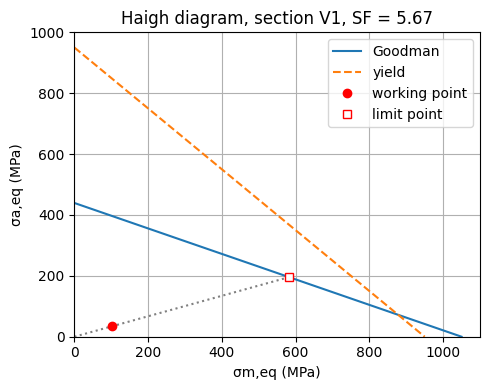

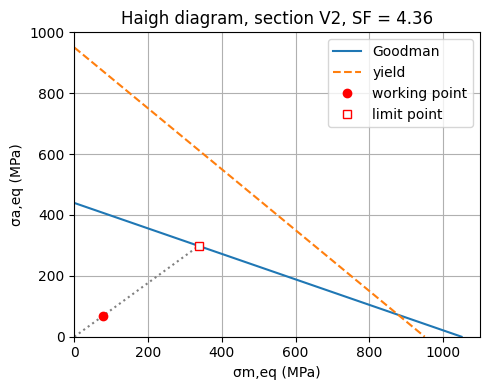

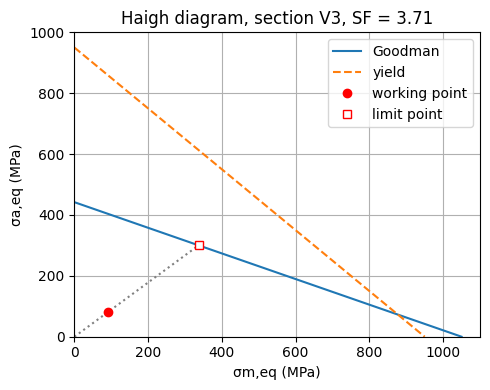

In [12]:
for name, f in fatigue.items():
    sm, sa = f["sm_eq"], f["sa_eq"]
    k = f["SF_goodman"]

    plt.figure(figsize=(5, 4))
    plt.plot([0, SU_SHAFT], [f["sD"], 0], label="Goodman")
    plt.plot([0, SY_SHAFT], [SY_SHAFT, 0], "--", label="yield")
    plt.plot([0, k * sm], [0, k * sa], ":", color="gray")
    plt.plot(sm, sa, "ro", label="working point")
    plt.plot(k * sm, k * sa, "rs", mfc="white", label="limit point")

    plt.xlim(0, 1100)
    plt.ylim(0, 1000)
    plt.xlabel("σm,eq (MPa)")
    plt.ylabel("σa,eq (MPa)")
    plt.title(f"Haigh diagram, section {name}, SF = {k:.2f}")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.savefig(FIG / f"haigh_{name}.png", dpi=150)
    plt.show()

## 8. AGMA check of pinions R1 and R3

$$\sigma_{b}=F_tK_OK_BK_vK_HK_s\frac{1}{b\,m_tY_J},\qquad S_F=\frac{\sigma_{FP}}{\sigma_b}\frac{Y_N}{Y_\theta Y_Z}$$
$$\sigma_{H}=Z_E\sqrt{F_tK_OK_vK_s\frac{K_H}{b\,d_P}\frac{Z_R}{Z_I}},\qquad S_H=\frac{\sigma_{HP}}{\sigma_H}\frac{Z_NZ_W}{Y_\theta Y_Z}$$

R3 sits on P, so its pitch-line velocity is computed from the spindle P speed, not the input speed

In [13]:
def line(table, x):
    (x0, y0), (x1, y1) = sorted(table.items())
    return y0 + (y1 - y0) * (x - x0) / (x1 - x0)


gears = {}
for pinion, gear, Ft, w in (("R1", "R2", Ft12, omega["A1"]), ("R3", "R4", Ft34, omega["P"])):
    b, dp, dg = FACE, d[pinion], d[gear]
    mg = Z[gear] / Z[pinion]
    mat = GEAR_MAT[pinion]

    # dynamic factor Kv (V in ft/min inside the formula)
    V = abs(w) * r[pinion] / 1000                     # m/s
    B = 0.25 * (12 - QV) ** (2 / 3)
    A = 50 + 56 * (1 - B)
    Kv = ((A + sqrt(196.85 * V)) / A) ** B

    # load distribution factor KH (inches; F = 1.18 in, so the 1 < F <= 17 in formula)
    F_in = b / 25.4
    Cpf = max(F_in / (10 * dp / 25.4), 0.05) - 0.0375 + 0.0125 * F_in
    Cma = 0.127 + 0.0158 * F_in - 0.930e-4 * F_in ** 2   # commercial enclosed
    KH = 1 + CMC * (Cpf * CPM[pinion] + Cma * CE)

    # size factor Ks (Lewis Y at the virtual number of teeth)
    zv = Z[pinion] / cos(PSI) ** 3
    Y = np.interp(zv, list(LEWIS_Y), list(LEWIS_Y.values()))
    Ks = 0.843 * (b * MT * sqrt(Y)) ** 0.0535

    # rim thickness factor KB
    if pinion == "R1":
        KB = 1.0                                      # pinion cut on the shaft
    else:
        mB = (dp - 2.5 * MN - R3_HUB_D) / 2 / (2.25 * MN)
        KB = 1.0 if mB >= 1.2 else 1.6 * log(2.242 / mB)

    # geometry factor YJ = J' * J''
    YJ = line(J1, Z[pinion]) * line(J2, Z[gear])

    # bending
    s_bend = Ft * K0 * Kv * Ks * KH * KB / (b * MT * YJ)
    YN = 1.3558 * N_CYCLES ** -0.0178
    SF = mat["sFP"] * YN / (Y_THETA * YZ * s_bend)

    # pitting geometry factor ZI
    rp, rg = dp / 2, dg / 2
    C = (rp + rg) * sin(PHI_T)
    ZA = min(sqrt((rp + MN) ** 2 - (rp * cos(PHI_T)) ** 2), C)
    ZB = min(sqrt((rg + MN) ** 2 - (rg * cos(PHI_T)) ** 2), C)
    mN = pi * MN * cos(PHI_N) / (0.95 * (ZA + ZB - C))
    ZI = cos(PHI_T) * sin(PHI_T) / (2 * mN) * mg / (mg + 1)

    # pitting
    s_pit = ZE * sqrt(Ft * K0 * Kv * Ks * KH * ZR / (b * dp * ZI))
    ZN = 1.4488 * N_CYCLES ** -0.023
    hb = mat["HB"] / GEAR_MAT[gear]["HB"]
    Ap = 0.0 if hb < 1.2 else (8.98e-3 * hb - 8.29e-3 if hb <= 1.7 else 0.00698)
    ZW = 1 + Ap * (mg - 1)
    SH = mat["sHP"] * ZN * ZW / (Y_THETA * YZ * s_pit)

    gears[pinion] = dict(V=V, Kv=Kv, KH=KH, Ks=Ks, KB=KB, YJ=YJ, ZI=ZI,
                         s_bend=s_bend, SF=SF, s_pit=s_pit, SH=SH)
    print(f"{pinion}: V = {V:.2f} m/s  Kv = {Kv:.4f}  KH = {KH:.4f}  Ks = {Ks:.4f}  "
          f"KB = {KB:.2f}  YJ = {YJ:.4f}  ZI = {ZI:.4f}")
    print(f"    bending  sigma = {s_bend:7.2f} MPa   SF = {SF:.2f}")
    print(f"    pitting  sigma = {s_pit:7.2f} MPa   SH = {SH:.2f}")

R1: V = 6.27 m/s  Kv = 1.3711  KH = 1.1894  Ks = 1.0345  KB = 1.00  YJ = 0.4933  ZI = 0.2077
    bending  sigma =   41.01 MPa   SF = 7.62
    pitting  sigma =  444.33 MPa   SH = 1.84
R3: V = 1.63 m/s  Kv = 1.1946  KH = 1.1821  Ks = 1.0348  KB = 1.00  YJ = 0.4904  ZI = 0.1866
    bending  sigma =  137.31 MPa   SF = 3.20
    pitting  sigma =  832.26 MPa   SH = 1.57


## 9. SKF life of bearings A–D

- **Equivalent loads:**
 $P=F_r$ if $F_a/F_r\le e$, otherwise $P = 0.4F_r+YF_a$. 
 Static: $P_0=\max(0.5F_r+Y_0F_a,\;F_r)$, and $s_0 = C_0/P_0$.
- **Minimum load:** 
 $F_{rm}=0.017\,C$ 
 for Explorer bearings.
- **Rated viscosity** $\nu_1$ (ISO 281): 
$45000\,n^{-0.83}d_m^{-0.5}$ for $n<1000$ rpm,
 otherwise $4500\,n^{-0.5}d_m^{-0.5}$. Then $\kappa=\nu/\nu_1$.
- **$a_{SKF}$:** ISO 281 roller-bearing formula, evaluated at $1.39\,\eta_cP_u/P$ (Explorer axis), capped at 50.
- **Life:** 
$L_{5m}=a_1a_{SKF}(C/P)^{10/3}$ in millions of revolutions, $L_{5mh}=10^6L_{5m}/(60n)$.

In [14]:
for name, b in bear.items():
    cat = BEARINGS[b["series"]]
    Fr, Fa, n = b["Fr"], b["Fa"], b["n"]
    P = Fr if Fa / Fr <= cat["e"] else 0.4 * Fr + cat["Y"] * Fa
    P0 = max(0.5 * Fr + cat["Y0"] * Fa, Fr)
    Frm = FRM_FACTOR * cat["C"]
    dm = 0.5 * (cat["d"] + cat["D"])
    nu1 = 45000 * n ** -0.83 * dm ** -0.5 if n < 1000 else 4500 * n ** -0.5 * dm ** -0.5
    kappa = NU_OIL_60C / nu1
    x = ETA_C * cat["Pu"] / P
    if kappa < 0.4:
        c = 1.5859 - 1.3993 / kappa ** 0.054381
    elif kappa < 1:
        c = 1.5859 - 1.2348 / kappa ** 0.19087
    else:
        c = 1.5859 - 1.2348 / min(kappa, 4) ** 0.071739
    inner = 1 - c * (EXPLORER_SHIFT * x) ** 0.4
    aSKF = 50.0 if inner <= 0 else min(0.1 * inner ** -9.185, 50.0)
    L10 = (cat["C"] / P) ** (10 / 3)
    L5m = A1_RELIABILITY * aSKF * L10
    L5mh = 1e6 / (60 * n) * L5m
    b.update(FaFr=Fa / Fr, e=cat["e"], P=P, P0=P0, s0=cat["C0"] / P0, Frm=Frm, Frm_ok=Fr >= Frm, dm=dm,
             nu=NU_OIL_60C, nu1=nu1, kappa=kappa, etaPuP=x, aSKF=aSKF, L10=L10, L5m=L5m, L5mh=L5mh)
    print(f"{name} ({b['series']}, {n:6.1f} rpm): P = {P/1000:.3f} kN  s0 = {b['s0']:5.2f}  kappa = {kappa:.2f}  "
          f"aSKF = {aSKF:.2f}  L5mh = {L5mh:9.0f} h  (Fr >= Frm: {Fr >= Frm})")

A (30203, 2500.0 rpm): P = 2.032 kN  s0 = 13.54  kappa = 2.37  aSKF = 3.57  L5mh =     52614 h  (Fr >= Frm: True)
B (30203, 2500.0 rpm): P = 2.053 kN  s0 =  9.06  kappa = 2.37  aSKF = 3.51  L5mh =     49948 h  (Fr >= Frm: True)
C (30208,  229.7 rpm): P = 5.824 kN  s0 = 11.68  kappa = 0.63  aSKF = 0.85  L5mh =    205893 h  (Fr >= Frm: True)
D (30208,  229.7 rpm): P = 7.680 kN  s0 = 12.50  kappa = 0.63  aSKF = 0.67  L5mh =     63792 h  (Fr >= Frm: True)


## 10. Consistency checks

Each check gets the same result by a different route than the calculation above:
textbook formulas instead of the vector method, a separate hand moment equation about each support,
power conservation, pitch-line speeds, and stresses worked out by hand at known points.
If any check fails, the notebook stops with an error.

In [15]:
#Kinematics: same power on every shaft, same pitch-line speed on both gears of a mesh
for shaft in ("A1", "P", "A2"):
    assert np.isclose(T[shaft] * abs(omega[shaft]), P_IN)
v_12 = pi * d["R1"] * rpm["A1"] / 60000 #m/s, v = pi d n / 60000
v_34 = pi * d["R4"] * rpm["A2"] / 60000
assert np.isclose(v_12, pi * d["R2"] * abs(rpm["P"]) / 60000)
assert np.isclose(v_34, pi * d["R3"] * abs(rpm["P"]) / 60000)
assert np.isclose(gears["R1"]["V"], v_12) and np.isclose(gears["R3"]["V"], v_34)   #speeds used by AGMA

#Gear forces: the vector method agrees with the textbook formulas
for gear, Ft in (("R1", Ft12), ("R4", Ft34)):
    F_tan, F_rad, F_ax = np.abs(F[gear])
    assert np.isclose(F_tan, Ft)
    assert np.isclose(F_rad, Ft * tan(PHI_T))
    assert np.isclose(F_ax, Ft * tan(radians(20))) #tan of 20 degrees
assert np.allclose(F["R1"], -F["R2"]) and np.allclose(F["R4"], -F["R3"]) #action = reaction
assert F["R2"][2] * F["R3"][2] < 0     # R2, R3 same hand: thrusts on P oppose

#Support reactions by hand: one moment equation about each support 
#moment about x of a force Fy at z: -z*Fy;  moment about y of a force Fx at z: +z*Fx
Fx1, Fy1, M1 = F["R1"][0], F["R1"][1], Mx_axial["A1"]
RxA_hand = (A1_ZR1 - A1_ZB) * Fx1 / A1_ZB # moments about B
RxB_hand = -A1_ZR1 * Fx1 / A1_ZB  # moments about A
RyA_hand = ((A1_ZR1 - A1_ZB) * Fy1 - M1) / A1_ZB
RyB_hand = (M1 - A1_ZR1 * Fy1) / A1_ZB

Fx4, Fy4, M4, Fyo, L = F["R4"][0], F["R4"][1], Mx_axial["A2"], Fout[1], A2_ZD - A2_ZC
RxC_hand = (A2_ZR - A2_ZD) * Fx4 / L  # moments about D
RxD_hand = -(A2_ZR - A2_ZC) * Fx4 / L   # moments about C
RyC_hand = ((A2_ZR - A2_ZD) * Fy4 + (A2_ZOUT - A2_ZD) * Fyo - M4) / L
RyD_hand = (M4 - (A2_ZR - A2_ZC) * Fy4 - (A2_ZOUT - A2_ZC) * Fyo) / L

assert np.allclose([RxA, RyA, RxB, RyB], [RxA_hand, RyA_hand, RxB_hand, RyB_hand])
assert np.allclose([RxC, RyC, RxD, RyD], [RxC_hand, RyC_hand, RxD_hand, RyD_hand])
# each hand reaction came from its own moment equation, so the force balance is a real test
assert np.isclose(RxA_hand + RxB_hand + Fx1, 0, atol=1e-6) and np.isclose(RyA_hand + RyB_hand + Fy1, 0, atol=1e-6)
assert np.isclose(RxC_hand + RxD_hand + Fx4, 0, atol=1e-6) and np.isclose(RyC_hand + RyD_hand + Fy4 + Fyo, 0, atol=1e-6)

# Internal loads of A2 at points worked out by hand 
assert np.isclose(section_loads["V1"]["N"], -F["R4"][2]) # only R4 is left of V1
assert np.isclose(section_loads["V1"]["Mx"], M4)  # only its axial couple bends it
assert np.isclose(section_loads["V2"]["Mt"], T["A2"] * 1000) # full torque between R4 and L3
assert np.isclose(Mb_z.max(), abs(Fyo) * (A2_ZOUT - A2_ZD))     # max moment at D: end force x overhang
assert abs(zz[np.argmax(Mb_z)] - A2_ZD) < 0.1
assert np.allclose([N_z[-1], Mx_z[-1], My_z[-1], Mt_z[-1]], 0, atol=1e-6)  # nothing left at the free end

# Static stress at V1 by hand (keyseat: 35 - 5 = 30 mm)
assert np.isclose(static_sections["V1"]["tau"], 16 * T["A2"] * 1000 / (pi * 30 ** 3))

# Bearings: SKF requirements for a back-to-back pair
for name, b in bear.items():
    Y = BEARINGS[b["series"]]["Y"]
    assert b["Fa"] >= 0.5 * b["Fr"] / Y - 1e-9 # never below its own induced thrust 0.5 Fr/Y
assert np.isclose(-bear["A"]["Fa"] + bear["B"]["Fa"] + Ka_A1, 0, atol=1e-6) # axial balance of A1
assert np.isclose(RzC + RzD + F["R4"][2] + Fout[2], 0, atol=1e-6)  # axial balance of A2

print("all checks passed")
print(f"reactions by hand (N): RxC = {RxC_hand:.1f}, RyC = {RyC_hand:.1f}, RxD = {RxD_hand:.1f}, RyD = {RyD_hand:.1f}")

all checks passed
reactions by hand (N): RxC = -5806.6, RyC = -450.0, RxD = 2129.1, RyD = -3469.3
